# Stage 6a — Results Summary

Loads the outputs already saved by Stages 1-5 (no models are refit here) and produces
presentation-ready figures plus a single numbers file (`reports/results_summary.md`) so
the README, a deck, and this notebook all cite the same values.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

sns.set_theme(style="white")
PALETTE = sns.color_palette("colorblind")
TREATED_COLOR = PALETTE[3]
CONTROL_COLOR = PALETTE[0]
NEUTRAL_COLOR = PALETTE[0]
ACCENT_COLOR = PALETTE[2]

FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42


def save_fig(fig, name):
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path}")


results = {}  # accumulates every headline number for results_summary.md, in display order


## Load saved outputs

Everything below comes from files already written by earlier stages:
`data/raw/*.parquet` (Stage 1), `data/processed/model_table.parquet` (Stage 2),
`segments.parquet` (Stage 3), `propensity_scores.parquet` (Stage 4), and
`uplift_scores_spend.parquet` + `ate_estimates.csv` (Stage 5).


In [2]:
campaigns = pd.read_parquet("../data/raw/campaigns.parquet")
campaign_descriptions = pd.read_parquet("../data/raw/campaign_descriptions.parquet")
coupon_redemptions = pd.read_parquet("../data/raw/coupon_redemptions.parquet")

model_table = pd.read_parquet("../data/processed/model_table.parquet")
segments = pd.read_parquet("../data/processed/segments.parquet")
propensity_scores = pd.read_parquet("../data/processed/propensity_scores.parquet")
ate_estimates = pd.read_csv("../data/processed/ate_estimates.csv")
uplift_scores_spend = pd.read_parquet("../data/processed/uplift_scores_spend.parquet")

campaign_18 = model_table[model_table["campaign_id"] == 18].merge(
    segments[["household_id", "segment_name"]], on="household_id", how="left"
)
print("All files loaded.")


All files loaded.


## 1. Campaign overview

Targeted households and redemption rate for the three Type A campaigns, computed from
the raw campaign/redemption tables (matches Stage 1 exactly).


In [3]:
campaign_overview = pd.DataFrame({
    "targeted_households": campaigns.groupby("campaign_id")["household_id"].nunique(),
    "redeeming_households": coupon_redemptions.groupby("campaign_id")["household_id"].nunique(),
}).loc[[8, 13, 18]]
campaign_overview["redemption_rate"] = campaign_overview["redeeming_households"] / campaign_overview["targeted_households"]
campaign_overview


,targeted_households,redeeming_households,redemption_rate
campaign_id,,,
8,1076,158.0,0.146840
13,1077,196.0,0.181987
18,1133,214.0,0.188879


saved ..\reports\figures\01_campaign_overview.png


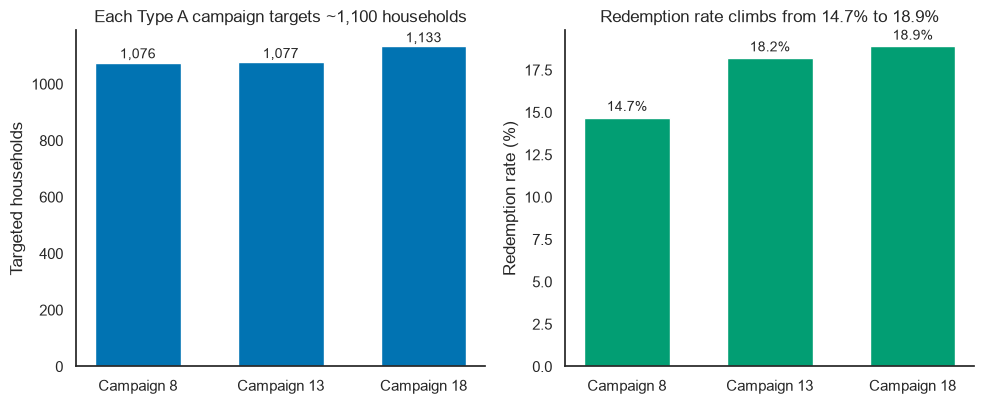

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
campaign_labels = [f"Campaign {c}" for c in campaign_overview.index]

axes[0].bar(campaign_labels, campaign_overview["targeted_households"], color=NEUTRAL_COLOR, width=0.6)
for i, v in enumerate(campaign_overview["targeted_households"]):
    axes[0].text(i, v + 15, f"{v:,}", ha="center", fontsize=10)
axes[0].set_title("Each Type A campaign targets ~1,100 households")
axes[0].set_ylabel("Targeted households")
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].bar(campaign_labels, campaign_overview["redemption_rate"] * 100, color=ACCENT_COLOR, width=0.6)
for i, v in enumerate(campaign_overview["redemption_rate"]):
    axes[1].text(i, v * 100 + 0.4, f"{v:.1%}", ha="center", fontsize=10)
axes[1].set_title("Redemption rate climbs from 14.7% to 18.9%")
axes[1].set_ylabel("Redemption rate (%)")
axes[1].spines[["top", "right"]].set_visible(False)

fig.tight_layout()
save_fig(fig, "01_campaign_overview.png")
plt.show()

results["campaign_overview"] = campaign_overview.round(4)


## 2. Treated vs. control profile (selection bias)

Key pre-campaign features, campaign 18, treated vs. control — the same imbalance
documented throughout Stages 2, 3 and 5, shown here as a single presentation chart.


saved ..\reports\figures\02_treated_vs_control_profile.png


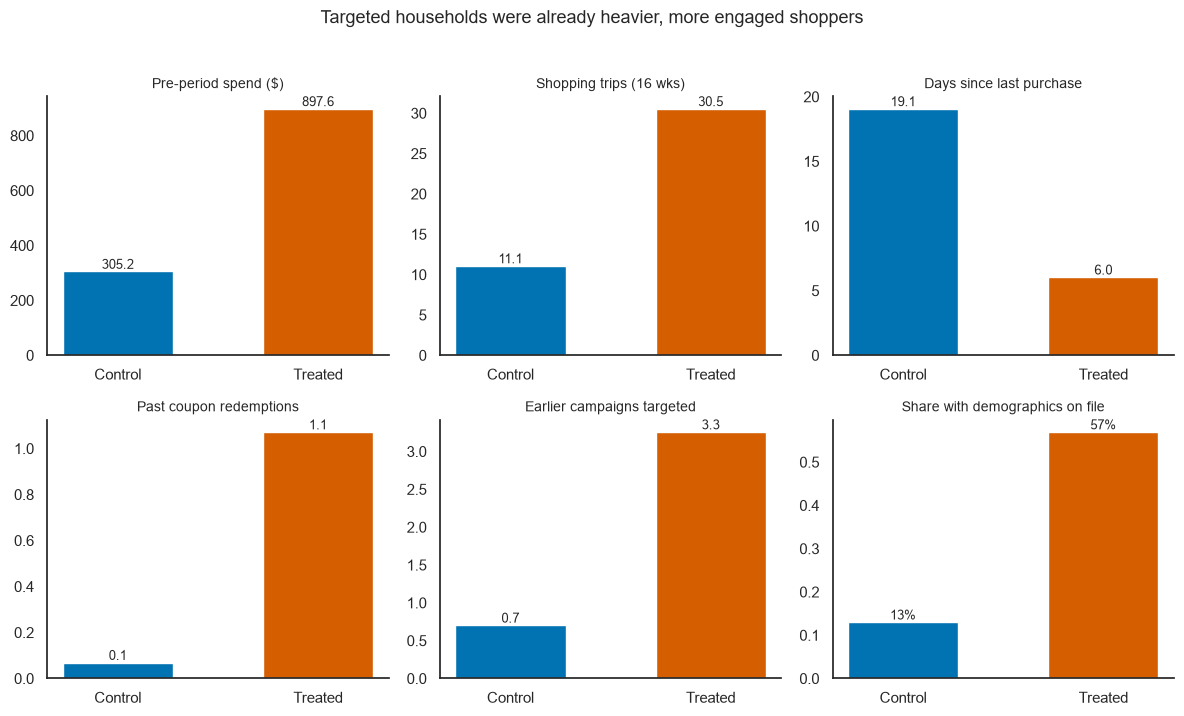

In [5]:
PROFILE_FEATURES = [
    ("monetary_spend", "Pre-period spend ($)"),
    ("frequency_baskets", "Shopping trips (16 wks)"),
    ("recency_days", "Days since last purchase"),
    ("past_redemptions_count", "Past coupon redemptions"),
    ("earlier_campaigns_count", "Earlier campaigns targeted"),
    ("has_demographics", "Share with demographics on file"),
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (feature, label) in zip(axes.flat, PROFILE_FEATURES):
    control_mean = campaign_18.loc[campaign_18["treated"] == 0, feature].mean()
    treated_mean = campaign_18.loc[campaign_18["treated"] == 1, feature].mean()
    bars = ax.bar(["Control", "Treated"], [control_mean, treated_mean], color=[CONTROL_COLOR, TREATED_COLOR], width=0.55)
    is_share = feature == "has_demographics"
    for bar, val in zip(bars, [control_mean, treated_mean]):
        label_text = f"{val:.0%}" if is_share else f"{val:,.1f}"
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), label_text, ha="center", va="bottom", fontsize=9)
    ax.set_title(label, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xticks([0, 1])

fig.suptitle("Targeted households were already heavier, more engaged shoppers", y=1.02, fontsize=13)
fig.tight_layout()
save_fig(fig, "02_treated_vs_control_profile.png")
plt.show()

results["treated_vs_control_profile"] = pd.DataFrame(
    {
        feature: {
            "control_mean": campaign_18.loc[campaign_18["treated"] == 0, feature].mean(),
            "treated_mean": campaign_18.loc[campaign_18["treated"] == 1, feature].mean(),
        }
        for feature, _ in PROFILE_FEATURES
    }
).T.round(3)


## 3. Segment profiles: heatmap + summary table


saved ..\reports\figures\03_segment_heatmap.png


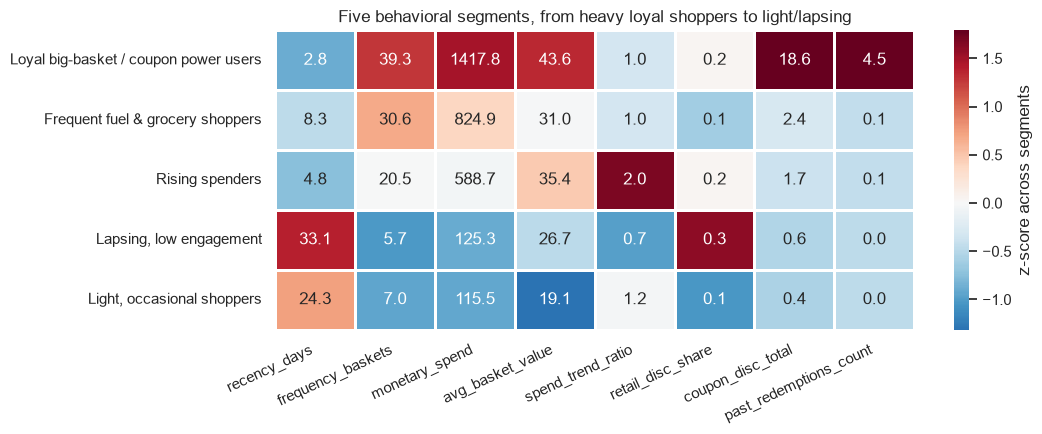

In [6]:
SEGMENT_BEHAVIORAL_COLS = [
    "recency_days", "frequency_baskets", "monetary_spend", "avg_basket_value",
    "spend_trend_ratio", "retail_disc_share", "coupon_disc_total", "past_redemptions_count",
]
SEGMENT_ORDER = [
    "Loyal big-basket / coupon power users", "Frequent fuel & grocery shoppers",
    "Rising spenders", "Lapsing, low engagement", "Light, occasional shoppers",
]

segment_profile = campaign_18.groupby("segment_name")[SEGMENT_BEHAVIORAL_COLS].mean().loc[SEGMENT_ORDER]
z_profile = segment_profile.apply(lambda col: (col - col.mean()) / col.std(), axis=0)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(
    z_profile, annot=segment_profile.values, fmt=".1f", cmap="RdBu_r", center=0,
    linewidths=2, linecolor="white", cbar_kws={"label": "z-score across segments"}, ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Five behavioral segments, from heavy loyal shoppers to light/lapsing")
plt.xticks(rotation=25, ha="right")
fig.tight_layout()
save_fig(fig, "03_segment_heatmap.png")
plt.show()


In [7]:
segment_table = campaign_18.groupby("segment_name").agg(
    size=("household_id", "size"), pct_targeted=("treated", "mean"),
).loc[SEGMENT_ORDER]
redemption_by_segment = (
    campaign_18[campaign_18["treated"] == 1].groupby("segment_name")["redeemed"].mean().rename("redemption_rate")
)
segment_table = segment_table.join(redemption_by_segment).round(3)
results["segment_table"] = segment_table
segment_table


,size,pct_targeted,redemption_rate
segment_name,,,
Loyal big-basket / coupon power users,266,0.906,0.552
Frequent fuel & grocery shoppers,504,0.629,0.123
Rising spenders,857,0.531,0.075
"Lapsing, low engagement",399,0.150,0.100
"Light, occasional shoppers",318,0.176,0.036


## 4. Propensity (redemption) model: cumulative gains

Calibrated XGBoost (Stage 4's winning model) vs. the simple "rank by past redemptions"
baseline, on campaign 18's targeted households.


saved ..\reports\figures\04_propensity_cumulative_gains.png


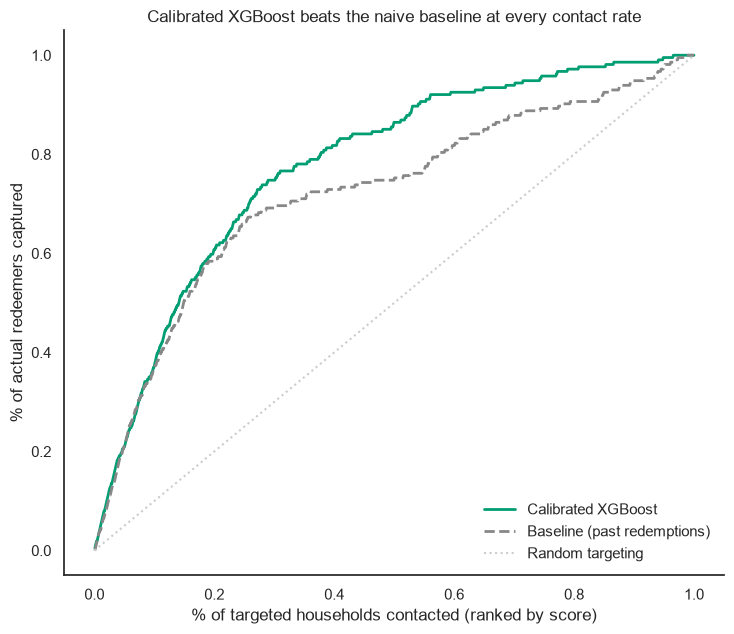

,roc_auc,pr_auc,top_decile_lift
Calibrated XGBoost,0.8441,0.6290,3.7213
Baseline (past redemptions),0.7803,0.5259,3.7213


In [8]:
scored = model_table[(model_table["campaign_id"] == 18) & (model_table["treated"] == 1)].merge(
    propensity_scores, on="household_id", how="inner"
)
y_true = scored["redeemed"].to_numpy()
total_redeemers = y_true.sum()

fig, ax = plt.subplots(figsize=(7.5, 6.5))
model_metrics = {}
for name, score_col, color, style in [
    ("Calibrated XGBoost", "propensity", ACCENT_COLOR, "-"),
    ("Baseline (past redemptions)", "past_redemptions_count", "#888888", "--"),
]:
    score = scored[score_col].to_numpy()
    order = np.argsort(-score)
    y_sorted = y_true[order]
    cum_gains = np.cumsum(y_sorted) / total_redeemers
    pct_contacted = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
    ax.plot(pct_contacted, cum_gains, label=name, color=color, linewidth=2, linestyle=style)

    n_decile = max(1, int(len(y_sorted) * 0.1))
    model_metrics[name] = {
        "roc_auc": roc_auc_score(y_true, score),
        "pr_auc": average_precision_score(y_true, score),
        "top_decile_lift": y_sorted[:n_decile].mean() / y_true.mean(),
    }

ax.plot([0, 1], [0, 1], linestyle=":", color="#cccccc", label="Random targeting")
ax.set_xlabel("% of targeted households contacted (ranked by score)")
ax.set_ylabel("% of actual redeemers captured")
ax.set_title("Calibrated XGBoost beats the naive baseline at every contact rate")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "04_propensity_cumulative_gains.png")
plt.show()

results["propensity_model_metrics"] = pd.DataFrame(model_metrics).T.round(4)
results["propensity_model_metrics"]


## 5. Naive vs. IPW vs. AIPW effect estimates (binary outcome)

Point estimates with bootstrapped 95% CIs for the binary outcome
(`bought_coupon_product`), from `ate_estimates.csv` (Stage 5).


saved ..\reports\figures\05_ate_estimates_binary.png


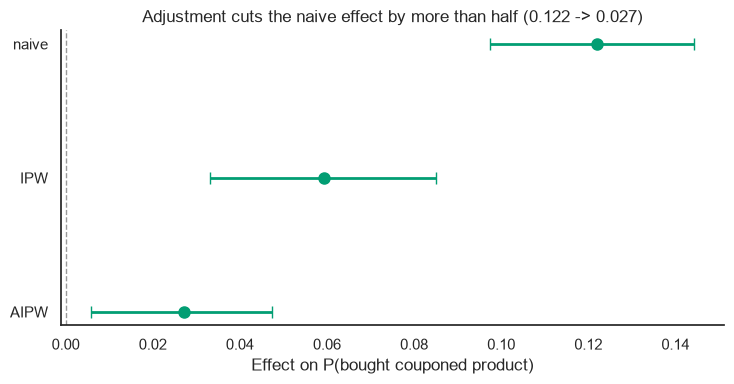

In [9]:
binary_estimates = ate_estimates[ate_estimates["outcome"] == "bought_coupon_product"].set_index("estimator").loc[
    ["naive", "IPW", "AIPW"]
]

fig, ax = plt.subplots(figsize=(7.5, 4))
y_pos = np.arange(len(binary_estimates))
ax.errorbar(
    binary_estimates["estimate"], y_pos,
    xerr=[binary_estimates["estimate"] - binary_estimates["ci_low"], binary_estimates["ci_high"] - binary_estimates["estimate"]],
    fmt="o", color=ACCENT_COLOR, ecolor=ACCENT_COLOR, elinewidth=2, capsize=4, markersize=8,
)
ax.axvline(0, color="#999999", linewidth=1, linestyle="--")
ax.set_yticks(y_pos)
ax.set_yticklabels(binary_estimates.index)
ax.invert_yaxis()
ax.set_xlabel("Effect on P(bought couponed product)")
ax.set_title("Adjustment cuts the naive effect by more than half (0.122 -> 0.027)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "05_ate_estimates_binary.png")
plt.show()

results["binary_ate_estimates"] = binary_estimates.round(4)


## 6. Uplift by decile ($ outcome) and the Qini curve

Recomputed directly from the saved household-level `uplift_spend` scores and outcomes —
no model refit needed.


saved ..\reports\figures\06_uplift_decile_and_qini.png


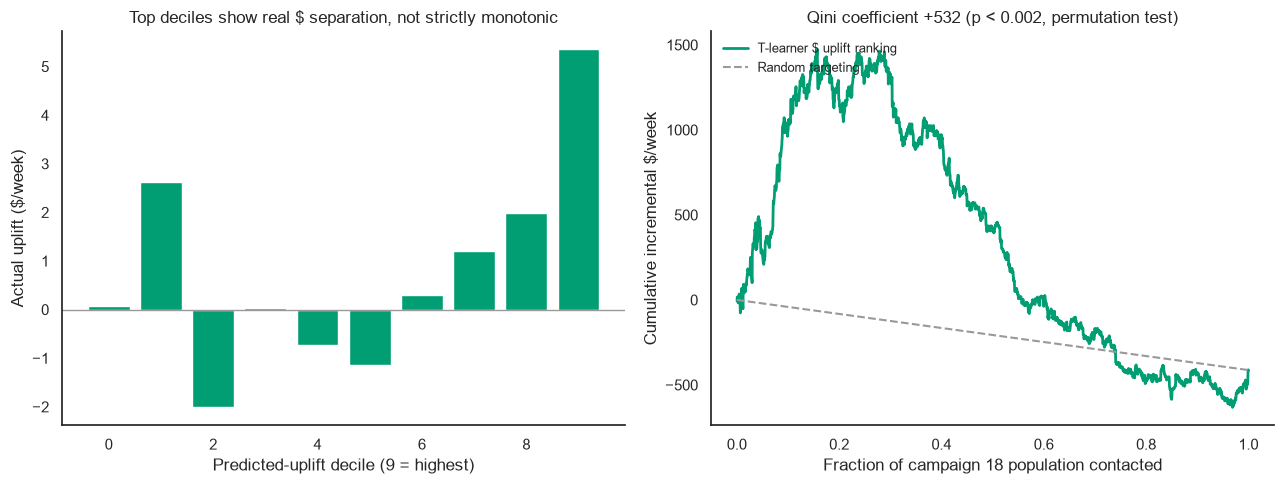

In [10]:
uplift_scores_spend["decile"] = pd.qcut(uplift_scores_spend["uplift_spend"], 10, labels=False, duplicates="drop")

decile_table = uplift_scores_spend.groupby("decile").apply(
    lambda g: pd.Series({
        "n": len(g),
        "n_treated": int(g["treated"].sum()),
        "n_control": int((g["treated"] == 0).sum()),
        "treated_share": g["treated"].mean(),
        "actual_treated_mean": g.loc[g["treated"] == 1, "change_weekly_coupon_spend"].mean(),
        "actual_control_mean": g.loc[g["treated"] == 0, "change_weekly_coupon_spend"].mean(),
    }),
    include_groups=False,
).sort_index(ascending=True)  # 0 = lowest predicted uplift, 9 = highest
decile_table["actual_uplift"] = decile_table["actual_treated_mean"] - decile_table["actual_control_mean"]


def qini_curve_values(df, score_col, outcome_col):
    d = df.sort_values(score_col, ascending=False).reset_index(drop=True)
    treated_arr = d["treated"].to_numpy()
    outcome_arr = d[outcome_col].to_numpy()
    cum_treated = np.cumsum(treated_arr)
    cum_control = np.cumsum(1 - treated_arr)
    cum_treated_sum = np.cumsum(outcome_arr * treated_arr)
    cum_control_sum = np.cumsum(outcome_arr * (1 - treated_arr))
    ratio = np.where(cum_control > 0, cum_treated / np.maximum(cum_control, 1), 0)
    qini = cum_treated_sum - cum_control_sum * ratio
    fraction = np.arange(1, len(d) + 1) / len(d)
    return fraction, qini


x, q = qini_curve_values(uplift_scores_spend, "uplift_spend", "change_weekly_coupon_spend")
qini_coefficient = np.trapezoid(q - x * q[-1], x)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bars = axes[0].bar(decile_table.index, decile_table["actual_uplift"], color=ACCENT_COLOR)
axes[0].axhline(0, color="#999999", linewidth=1)
axes[0].set_xlabel("Predicted-uplift decile (9 = highest)")
axes[0].set_ylabel("Actual uplift ($/week)")
axes[0].set_title("Top deciles show real $ separation, not strictly monotonic")
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].plot(x, q, color=ACCENT_COLOR, linewidth=2, label="T-learner $ uplift ranking")
axes[1].plot([0, 1], [0, q[-1]], linestyle="--", color="#999999", label="Random targeting")
axes[1].set_xlabel("Fraction of campaign 18 population contacted")
axes[1].set_ylabel("Cumulative incremental $/week")
axes[1].set_title(f"Qini coefficient +{qini_coefficient:.0f} (p < 0.002, permutation test)")
axes[1].legend(frameon=False, loc="upper left", fontsize=9)
axes[1].spines[["top", "right"]].set_visible(False)

fig.tight_layout()
save_fig(fig, "06_uplift_decile_and_qini.png")
plt.show()

results["spend_decile_table"] = decile_table.round(3)
results["qini_coefficient_spend"] = qini_coefficient


## 7. Treated share by uplift decile

The mechanism behind the decile-vs-pooled-estimate reconciliation (Stage 5, section
8a-iii-a): treated share rises sharply with predicted uplift.


saved ..\reports\figures\07_treated_share_by_decile.png


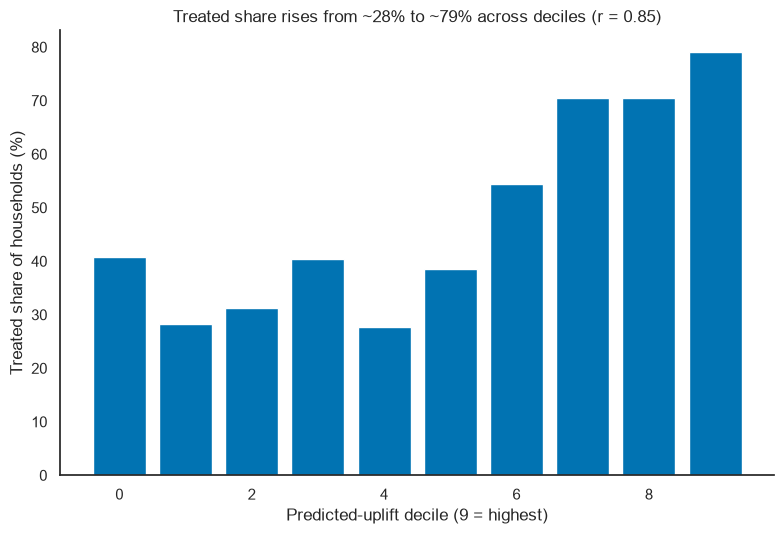

In [11]:
treated_share_corr = np.corrcoef(decile_table.index, decile_table["treated_share"])[0, 1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.bar(decile_table.index, decile_table["treated_share"] * 100, color=NEUTRAL_COLOR)
ax.set_xlabel("Predicted-uplift decile (9 = highest)")
ax.set_ylabel("Treated share of households (%)")
ax.set_title(f"Treated share rises from ~28% to ~79% across deciles (r = {treated_share_corr:.2f})")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "07_treated_share_by_decile.png")
plt.show()

results["treated_share_by_decile_corr"] = treated_share_corr


## Write `reports/results_summary.md`

Every number above, assembled from the exact objects used to build the figures (not
retyped), so the README and any deck draw from the same source.


In [12]:
permutation_rng = np.random.RandomState(RANDOM_STATE)
treated_original = uplift_scores_spend["treated"].to_numpy().copy()
permutation_coefs = []
for _ in range(500):
    shuffled = uplift_scores_spend.copy()
    shuffled["treated"] = permutation_rng.permutation(treated_original)
    xs, qs = qini_curve_values(shuffled, "uplift_spend", "change_weekly_coupon_spend")
    permutation_coefs.append(np.trapezoid(qs - xs * qs[-1], xs))
permutation_p_value = (np.array(permutation_coefs) >= qini_coefficient).mean()
results["qini_permutation_p_value"] = permutation_p_value
print(f"Permutation p-value recomputed: {'< 0.002' if permutation_p_value == 0 else permutation_p_value}")


Permutation p-value recomputed: < 0.002


In [13]:
lines = []
lines.append("# Results summary")
lines.append("")
lines.append("Every headline number from this project in one place. Generated by "
             "`notebooks/06_results_summary.ipynb` from the saved Stage 1-5 outputs -- "
             "not retyped by hand, so these numbers and the figures in `reports/figures/` "
             "are guaranteed to match.")
lines.append("")

lines.append("## 1. Campaign overview")
lines.append("")
lines.append(results["campaign_overview"].to_markdown())
lines.append("")

lines.append("## 2. Treated vs. control profile (campaign 18)")
lines.append("")
lines.append(results["treated_vs_control_profile"].to_markdown())
lines.append("")

lines.append("## 3. Segments (campaign 18)")
lines.append("")
lines.append(results["segment_table"].to_markdown())
lines.append("")

lines.append("## 4. Propensity (redemption) model, campaign 18 targeted households")
lines.append("")
lines.append(results["propensity_model_metrics"].to_markdown())
lines.append("")

lines.append("## 5. Binary-outcome effect estimates (naive / IPW / AIPW)")
lines.append("")
lines.append(results["binary_ate_estimates"].to_markdown())
lines.append("")

lines.append("## 6. $-outcome uplift by decile")
lines.append("")
lines.append(results["spend_decile_table"].to_markdown())
lines.append("")
lines.append(f"- Qini coefficient: **{results['qini_coefficient_spend']:.1f}**")
p_val = results["qini_permutation_p_value"]
lines.append(f"- Permutation test p-value (500 shuffles of treatment): "
             f"**{'< 0.002' if p_val == 0 else f'{p_val:.3f}'}**")
lines.append("")

lines.append("## 7. Treated share by uplift decile")
lines.append("")
lines.append(f"- Correlation between predicted-uplift decile rank and treated share: "
             f"**{results['treated_share_by_decile_corr']:.2f}**")
lines.append("")

lines.append("## Figures")
lines.append("")
for fname, caption in [
    ("01_campaign_overview.png", "Campaign overview"),
    ("02_treated_vs_control_profile.png", "Treated vs. control profile"),
    ("03_segment_heatmap.png", "Segment profile heatmap"),
    ("04_propensity_cumulative_gains.png", "Propensity model cumulative gains"),
    ("05_ate_estimates_binary.png", "Naive / IPW / AIPW effect estimates"),
    ("06_uplift_decile_and_qini.png", "Uplift by decile and Qini curve"),
    ("07_treated_share_by_decile.png", "Treated share by uplift decile"),
]:
    lines.append(f"- `figures/{fname}` -- {caption}")
lines.append("")

report_path = Path("../reports/results_summary.md")
report_path.write_text("\n".join(lines), encoding="utf-8")
print(f"written {report_path}")


written ..\reports\results_summary.md
